# 02 - Modeling

Notebook ini menjelaskan proses training ensemble **CatBoost + LightGBM ordinal**. Kode utama berada di folder `scripts` agar dapat digunakan kembali.

## Alur model

1. CatBoost mempelajari klasifikasi lima kelas secara langsung.
2. Empat LightGBM mempelajari target ordinal: `y > 1`, `y > 2`, `y > 3`, dan `y > 4`.
3. Probabilitas kedua model digabungkan menggunakan bobot terbaik pada validation set.
4. Bias kelas ditambahkan untuk meningkatkan macro-F1.
5. Model final dilatih menggunakan seluruh data training.

## 1. Import library

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from scripts.feature_engineering import DamageFeatureEngineer, TARGET
from scripts.preprocess import audit_data, build_column_transformer, load_data
from scripts.train import MODEL_PATH, METADATA_PATH, RunConfig, train_model

## 2. Memeriksa data dan konfigurasi

In [2]:
train, test = load_data(ROOT_DIR / 'data')
audit_data(train, test)
config = RunConfig()
config

Ukuran train: (533465, 17)
Ukuran test : (228629, 16)

Distribusi target:
damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64


RunConfig(seed=42, validation_size=0.2, selection_size=140000, cat_search_iterations=160, cat_final_iterations=600, lgb_iterations=500, target_encoding_folds=3, target_encoding_smoothing=40.0, depth=7, cat_learning_rate=0.12, class_weight_exponent=0.25, threads=15, prefix_lengths=(3, 4, 5, 6, 7, 8))

## 3. Memeriksa feature engineering dan ColumnTransformer

Pemeriksaan dilakukan pada sampel kecil agar cepat. `ColumnTransformer` digunakan di dalam pipeline CatBoost untuk memisahkan preprocessing fitur kategorikal dan numerik.

In [3]:
X_sample = train.drop(columns=TARGET).head(1000)
feature_engineer = DamageFeatureEngineer()
engineered_sample = feature_engineer.fit_transform(X_sample)
processed_sample = build_column_transformer().fit_transform(engineered_sample)

print('Sebelum feature engineering:', X_sample.shape)
print('Setelah feature engineering:', engineered_sample.shape)
print('Setelah ColumnTransformer:', processed_sample.shape)
engineered_sample.head()

Sebelum feature engineering: (1000, 16)
Setelah feature engineering: (1000, 25)
Setelah ColumnTransformer: (1000, 25)


,district_id,vdcmun_id,ward_id,count_floors_pre_eq,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,...,building_prefix_4,building_prefix_5,building_prefix_6,building_prefix_7,building_prefix_8,age_is_999,age_clean,floor_height_ratio,area_per_floor,volume_proxy
0,28,2802,280202,3,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,...,2808,28080,280803,2808030,28080301,0,42,7.0,168.0,10584
1,31,3104,310416,2,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,...,3119,31190,311908,3119080,31190800,0,8,8.0,190.0,6080
2,31,3111,311106,2,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,...,3103,31030,310303,3103030,31030300,0,37,8.0,187.5,6000
3,28,2802,280206,2,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,...,2808,28080,280806,2808060,28080604,0,70,7.5,159.5,4785
4,29,2904,290404,1,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,...,2913,29130,291301,2913010,29130100,0,25,6.0,495.0,2970


## 4. Menjalankan training

Training penuh dapat memerlukan beberapa jam. Ubah nilai berikut menjadi `True` hanya ketika environment sudah siap.

In [4]:
RUN_FULL_TRAINING = True

if RUN_FULL_TRAINING:
    train_model()
else:
    print('Training belum dijalankan. Ubah RUN_FULL_TRAINING menjadi True.')

Ukuran train: (533465, 17)
Ukuran test : (228629, 16)

Distribusi target:
damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64
Seleksi model: 112000 train, 28000 validation


c:\Users\Jason\SML_StructureDamageClassification\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM untuk y > 1 selesai.


c:\Users\Jason\SML_StructureDamageClassification\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM untuk y > 2 selesai.


c:\Users\Jason\SML_StructureDamageClassification\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM untuk y > 3 selesai.


c:\Users\Jason\SML_StructureDamageClassification\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM untuk y > 4 selesai.
Bobot LightGBM: 0.40
Macro-F1 sebelum bias: 0.5478
Macro-F1 setelah bias: 0.5593
              precision    recall  f1-score   support

     Grade 1       0.65      0.71      0.68      2896
     Grade 2       0.41      0.42      0.42      3206
     Grade 3       0.42      0.48      0.45      5012
     Grade 4       0.52      0.54      0.53      6754
     Grade 5       0.77      0.68      0.72     10132

    accuracy                           0.58     28000
   macro avg       0.56      0.57      0.56     28000
weighted avg       0.59      0.58      0.59     28000

Training CatBoost final...
Membuat fitur LightGBM final...
LightGBM untuk y > 1 selesai.
LightGBM untuk y > 2 selesai.
LightGBM untuk y > 3 selesai.
LightGBM untuk y > 4 selesai.
Model disimpan di: C:\Users\Jason\SML_StructureDamageClassification\models\pipeline_model_ensemble.pkl


## 5. Hasil validasi

Setelah training selesai, nilai macro-F1, bobot ensemble, dan bias kelas tersimpan dalam `models/metadata.json`.

In [5]:
if METADATA_PATH.exists():
    metadata = pd.read_json(METADATA_PATH, typ='series')
    display(metadata['selection'])
else:
    print('metadata.json belum tersedia karena training belum dijalankan.')

{'ordinal_weight': 0.4,
 'log_bias': [-0.14400000000000002,
  0.17600000000000002,
  0.136,
  0.055999999999999,
  -0.224],
 'raw_macro_f1': 0.547813703685409,
 'calibrated_macro_f1': 0.559304139443203}

## 6. Feature importance CatBoost

Grafik berikut menjelaskan kontribusi fitur pada cabang CatBoost. Nilai ini bukan feature importance keseluruhan ensemble.

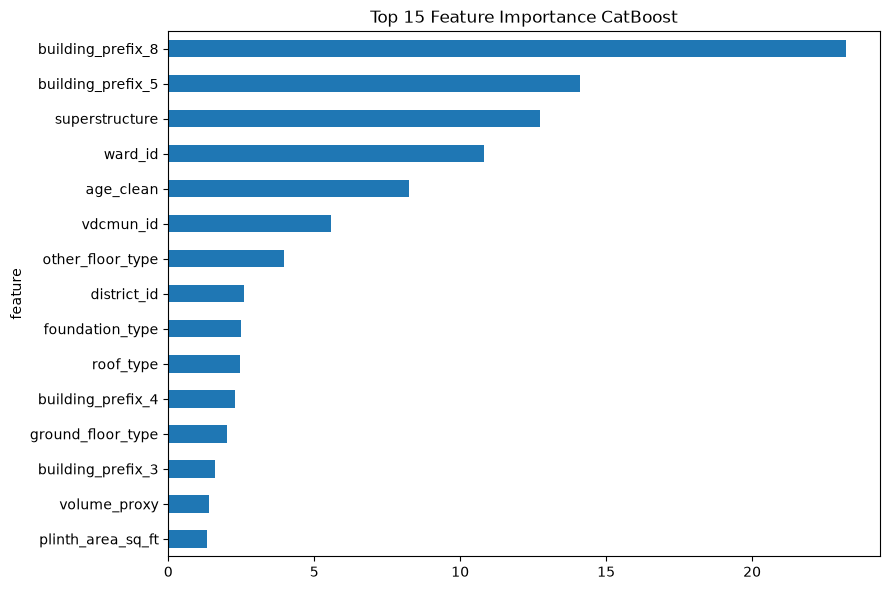

In [6]:
if MODEL_PATH.exists() and MODEL_PATH.stat().st_size > 0:
    artifact = joblib.load(MODEL_PATH)
    cat_pipeline = artifact['catboost_pipeline']
    feature_names = cat_pipeline.named_steps['preprocessor'].get_feature_names_out()
    importance = cat_pipeline.named_steps['model'].get_feature_importance()

    feature_importance = (
        pd.DataFrame({'feature': feature_names, 'importance': importance})
        .sort_values('importance', ascending=False)
        .head(15)
        .sort_values('importance')
    )

    feature_importance.plot.barh(
        x='feature', y='importance', legend=False, figsize=(9, 6)
    )
    plt.title('Top 15 Feature Importance CatBoost')
    plt.tight_layout()

    figure_path = ROOT_DIR / 'reports' / 'figures' / 'feature_importance.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(figure_path, dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Model belum tersedia. Jalankan training terlebih dahulu.')

## Interpretasi sementara

- CatBoost digunakan karena mampu menangani banyak fitur kategorikal.
- LightGBM ordinal memanfaatkan urutan alami tingkat kerusakan.
- Target encoding dibuat secara out-of-fold agar target validation tidak bocor ke data training.
- Macro-F1 dipakai karena setiap kelas dianggap sama pentingnya.
- Interpretasi final harus diperbarui menggunakan nilai pada `metadata.json` setelah training penuh selesai.